In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.transform import resize
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)


### Datos de entrada

Este modelo se entrenó utilizando imágenes de DBT previamente procesadas y almacenadas en formato `.npy`.

Los archivos de imágenes deben ubicarse en `datos_dbt/Imagenes/` y las etiquetas en `datos_dbt/Etiquetas/`.

Para el entrenamiento y la evaluación, las imágenes se redimensionan a 224 × 224 píxeles y se transforman en vectores unidimensionales.

Los resultados mostrados corresponden a la ejecución experimental original. Su reproducción exacta requiere los mismos conjuntos de datos y condiciones de ejecución.

In [ ]:
# ==========================================
# 1. CONFIGURACIÓN DE RUTAS
# ==========================================

from pathlib import Path

# Carpeta donde se encuentran los datos originales
DATA_DIR = Path("./datos_dbt")

DATA_DIR1 = DATA_DIR / "Imagenes"
DATA_DIR2 = DATA_DIR / "Etiquetas"

# Carpeta para guardar resultados
CKPT_DIR = DATA_DIR / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. CARGA DE DATASETS
# ==========================================

print("\n=== Cargando datasets ===")

X_train = np.load(os.path.join(DATA_DIR1, 'X_train_nuevo.npy'))
y_train = np.load(os.path.join(DATA_DIR2, 'y_train_nuevo.npy'))

X_val = np.load(os.path.join(DATA_DIR1, 'X_val.npy'))
y_val = np.load(os.path.join(DATA_DIR2, 'y_val.npy'))

X_test = np.load(os.path.join(DATA_DIR1, 'X_test_final.npy'))
y_test = np.load(os.path.join(DATA_DIR2, 'y_test_final.npy'))

print("\nTrain:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

print("\nDistribución entrenamiento:")
print(np.bincount(y_train))

print("\nDistribución validación:")
print(np.bincount(y_val))

print("\nDistribución test:")
print(np.bincount(y_test))



=== Cargando datasets ===

Train: (3197, 512, 512, 1)
Val  : (400, 512, 512, 1)
Test : (400, 512, 512, 1)

Distribución entrenamiento:
[1600 1597]

Distribución validación:
[200 200]

Distribución test:
[200 200]


In [ ]:

# ==========================================
# 3. PREPROCESAMIENTO
# ==========================================

def resize_dataset(X, size=(224, 224)):
    return np.array([
        resize(img, size, anti_aliasing=True).flatten()
        for img in X
    ])

print("\n=== Preprocesando imágenes ===")

X_train_small = resize_dataset(X_train)
X_val_small = resize_dataset(X_val)
X_test_small = resize_dataset(X_test)

print("Train:", X_train_small.shape)
print("Val  :", X_val_small.shape)
print("Test :", X_test_small.shape)

# ==========================================
# 4. ENTRENAMIENTO GAUSSIANNB
# ==========================================

print("\n=== Entrenando GaussianNB ===")

nb = GaussianNB()
nb.fit(X_train_small, y_train)




=== Preprocesando imágenes ===
Train: (3197, 50176)
Val  : (400, 50176)
Test : (400, 50176)

=== Entrenando GaussianNB ===


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09



=== MATRIZ DE CONFUSIÓN - TEST ===
[[169  31]
 [131  69]]

=== REPORTE DE CLASIFICACIÓN ===
                 precision    recall  f1-score   support

Sin estructuras       0.56      0.84      0.68       200
Con estructuras       0.69      0.34      0.46       200

       accuracy                           0.59       400
      macro avg       0.63      0.59      0.57       400
   weighted avg       0.63      0.59      0.57       400


=== RESULTADOS GAUSSIANNB - TEST ===
Accuracy      : 0.5950
Sensibilidad  : 0.3450
Especificidad : 0.8450
Precision     : 0.6900
F1-score      : 0.4600
AUC           : 0.5982


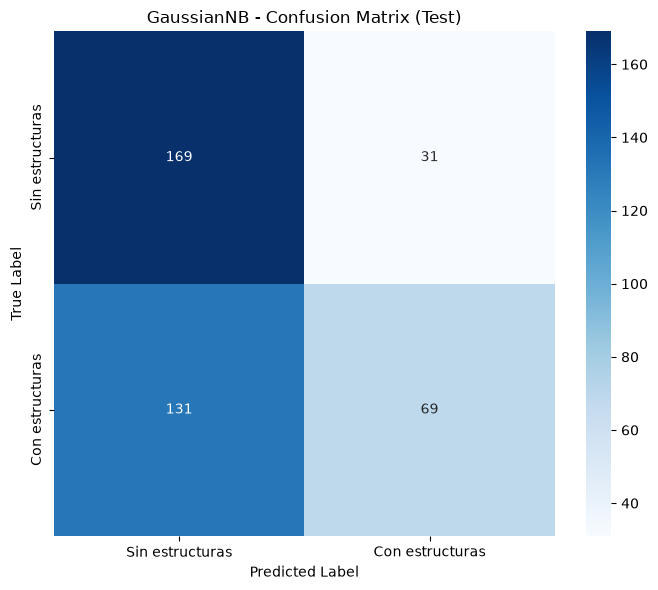

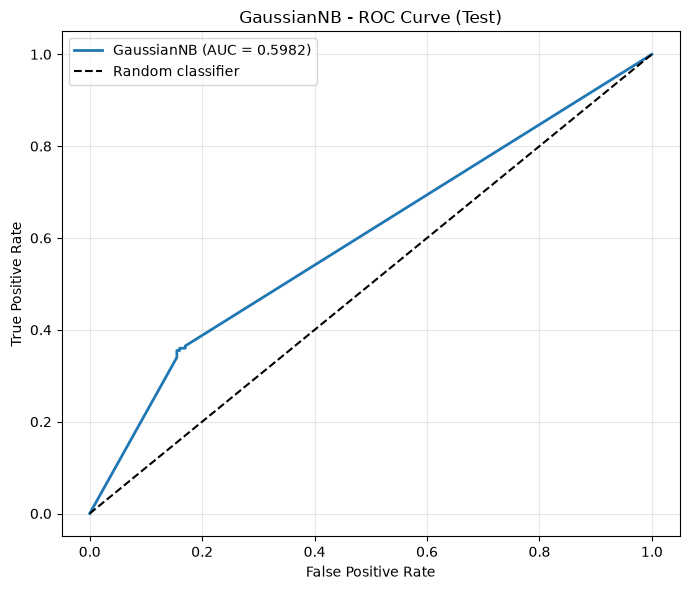

In [ ]:
# ==========================================
# 5. EVALUACIÓN EN TEST
# ==========================================

nb_predictions = nb.predict(X_test_small)

# Probabilidad de la clase positiva (1)
idx_positivo = np.where(nb.classes_ == 1)[0][0]
nb_prob = nb.predict_proba(X_test_small)[:, idx_positivo]

# ==========================================
# 6. MATRIZ DE CONFUSIÓN
# ==========================================

nb_cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = nb_cm.ravel()

print("\n=== MATRIZ DE CONFUSIÓN - TEST ===")
print(nb_cm)

print("\n=== REPORTE DE CLASIFICACIÓN ===")

print(
    classification_report(
        y_test,
        nb_predictions,
        labels=[0, 1],
        target_names=[
            "Sin estructuras",
            "Con estructuras"
        ],
        zero_division=0
    )
)

# ==========================================
# 7. MÉTRICAS
# ==========================================

accuracy = accuracy_score(y_test, nb_predictions)

sensibilidad = recall_score(
    y_test,
    nb_predictions,
    pos_label=1,
    zero_division=0
)

especificidad = (
    tn / (tn + fp) if (tn + fp) > 0 else np.nan
)

precision = precision_score(
    y_test,
    nb_predictions,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    nb_predictions,
    pos_label=1,
    zero_division=0
)

auc = roc_auc_score(y_test, nb_prob)

print("\n=== RESULTADOS GAUSSIANNB - TEST ===")

print(f"Accuracy      : {accuracy:.4f}")
print(f"Sensibilidad  : {sensibilidad:.4f}")
print(f"Especificidad : {especificidad:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"F1-score      : {f1:.4f}")
print(f"AUC           : {auc:.4f}")

# ==========================================
# 8. MATRIZ DE CONFUSIÓN - GRÁFICO
# ==========================================

plt.figure(figsize=(7, 6))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Sin estructuras", "Con estructuras"],
    yticklabels=["Sin estructuras", "Con estructuras"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("GaussianNB - Confusion Matrix (Test)")

plt.tight_layout()

plt.savefig(
    os.path.join(CKPT_DIR, "GaussianNB_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 9. CURVA ROC
# ==========================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    nb_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"GaussianNB (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GaussianNB - ROC Curve (Test)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(CKPT_DIR, "GaussianNB_ROC.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
